# Delaware accident history: source audit and exploratory analysis

This notebook reconstructs the original directed-edge history archive from the Delaware benchmark. It examines source coverage, directionality, feature distributions, fixed and rolling windows, and next-month associations. The exploratory period extends through December 2018 and overlaps the final test period. The training-only analysis and model comparisons on physical roads are in the [final report](../Final_Report.ipynb).

The monthly exports preserve both directed edges and their target counts. The training pipeline aggregates the counts by unordered endpoints before constructing physical-road features. [Dataset and feature definitions](../docs/accident_history.md).

## 1. Configuration and forecasting assumptions

- Predict one month ahead; prior-month accident reports are assumed available.
  Reporting delay would require longer lags.
- Use the supplied static graph's **ordered endpoint pairs**, preserving the
  benchmark's edge orientation and coalesced adjacency order. These are not OSM way IDs.
- The CSV contains positive road-month counts only. In months assumed usable,
  omitted graph pairs are interpreted as zero. This follows the benchmark convention;
  it does **not** independently verify reporting completeness or historical road existence.
- **2022-10 is excluded by default:** only 23 accidents are recorded, versus thousands
  in preceding months. It is suspected partial coverage, not a verified explanation.
  **2022-11/12 have no accident rows and remain unavailable**, not zero.
- Feature-target exploratory plots use **2009–2018 as a provisional development period**.
  The final report uses a separate training-only analysis.
  Later labels are used only for coverage auditing and mechanical feature export here.
- No target-month weather or traffic features are used. Their forecast-time availability
  must be checked separately if they are included in the group's forecasting models.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

import os

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/history/features.py').is_file())
sys.path.insert(0, str(ROOT))
from src.history.features import (FEATURE_NAMES, load_data, NeighbourAggregator,
                                  build_features, fixed_history_mean,
                                  walk_forward_indices, export_features, run_self_checks)

DATA_DIR = Path(os.environ.get('CS5284_DATA_DIR', ROOT / 'data')) / 'DE'
OUTPUT_DIR = Path(os.environ.get('CS5284_HISTORY_EDA_OUTPUT', ROOT / 'results/history_eda'))
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
LAST_USABLE_MONTH = '2022-09'
EDA_END_MONTH = '2018-12'  # Original exploratory cutoff; the final report uses training months only.
EXCLUDED_MONTHS = []     # add any further incomplete months confirmed by the team
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / name, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Python:', sys.version.split()[0])
print('State:', DATA_DIR.name)
print('Provisional EDA cutoff:', EDA_END_MONTH)

Python: 3.11.16
State: DE
Provisional EDA cutoff: 2018-12


## 2. Audit the source files and identifiers

`accidents_monthly.csv` supplies dates, endpoint IDs and counts.
`adj_matrix.pt` supplies the universe of graph edges and connectivity, including
roads absent from the accident CSV. A node table verifies the index-to-OSM-ID mapping.
The additional OSM files are not needed for this history milestone; joining new OSM
attributes is Vidurveer's work and requires a verified mapping to the benchmark graph.

In [2]:
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='TypedStorage is deprecated.*', category=UserWarning)
    data = load_data(DATA_DIR, LAST_USABLE_MONTH, EXCLUDED_MONTHS)
neighbours = NeighbourAggregator(data.edges[['node_1_idx', 'node_2_idx']].to_numpy(), len(data.nodes))
display(pd.Series({k: v for k, v in data.audit.items() if not isinstance(v, (dict, list))}, name='value').to_frame())
display(data.raw[['year', 'month', 'node_1', 'node_2', 'node_1_idx', 'node_2_idx', 'acc_count']].head())
display(data.monthly_audit.tail(15))
print('Missing months:', data.audit['missing_months'])
print('Graph edge mapping:')
display(data.edges.head())

,value
accident_rows,374987
recorded_accidents,458282
nodes,49023
ordered_graph_edges,116196
unordered_endpoint_groups,65252
self_loop_edges,640
self_loop_accident_rows,1
months_with_accident_rows,166
usable_months,165
last_usable_month,2022-09


,year,month,node_1,node_2,node_1_idx,node_2_idx,acc_count
0,2009,1,178554989,178607325,1650,2670,1
1,2009,1,178554993,178578310,13083,14658,2
2,2009,1,178556446,178556798,13142,13158,1
3,2009,1,178556483,178587379,13146,10330,3
4,2009,1,178556798,178562374,13158,13447,1


,month,has_accident_rows,usable_under_current_assumption,recorded_accidents,positive_road_month_rows,implicit_zero_fraction
153,2021-10,True,True,3471.0,2782.0,0.976058
154,2021-11,True,True,3587.0,2864.0,0.975352
155,2021-12,True,True,3268.0,2592.0,0.977693
156,2022-01,True,True,2713.0,2273.0,0.980438
157,2022-02,True,True,2635.0,2199.0,0.981075
158,2022-03,True,True,2851.0,2356.0,0.979724
159,2022-04,True,True,2837.0,2331.0,0.979939
160,2022-05,True,True,3282.0,2632.0,0.977349
161,2022-06,True,True,3164.0,2577.0,0.977822
162,2022-07,True,True,3149.0,2547.0,0.978080


Missing months: ['2022-11', '2022-12']
Graph edge mapping:


,edge_id,node_1_idx,node_2_idx,node_1,node_2
0,0,0,10,178623660,178661265
1,1,0,31,178623660,178703210
2,2,0,36,178623660,178706236
3,3,1,8,178627690,178660036
4,4,1,16,178627690,178674758


### Coverage and interpretation

There are fewer recorded accidents in 2009 than in later years; the data alone do not
establish whether that is genuine or a reporting change. Independent reporting records would be needed to resolve this. Do not automatically extrapolate partial-year totals or fill unavailable
months with zero. The supplied graph also contains self-loops; these are retained to
preserve edge alignment. Neighbour aggregation handles them explicitly.

The graph snapshot may include roads not present in every historical year. Without a
road-validity table, we use a fixed graph universe and document this limitation.

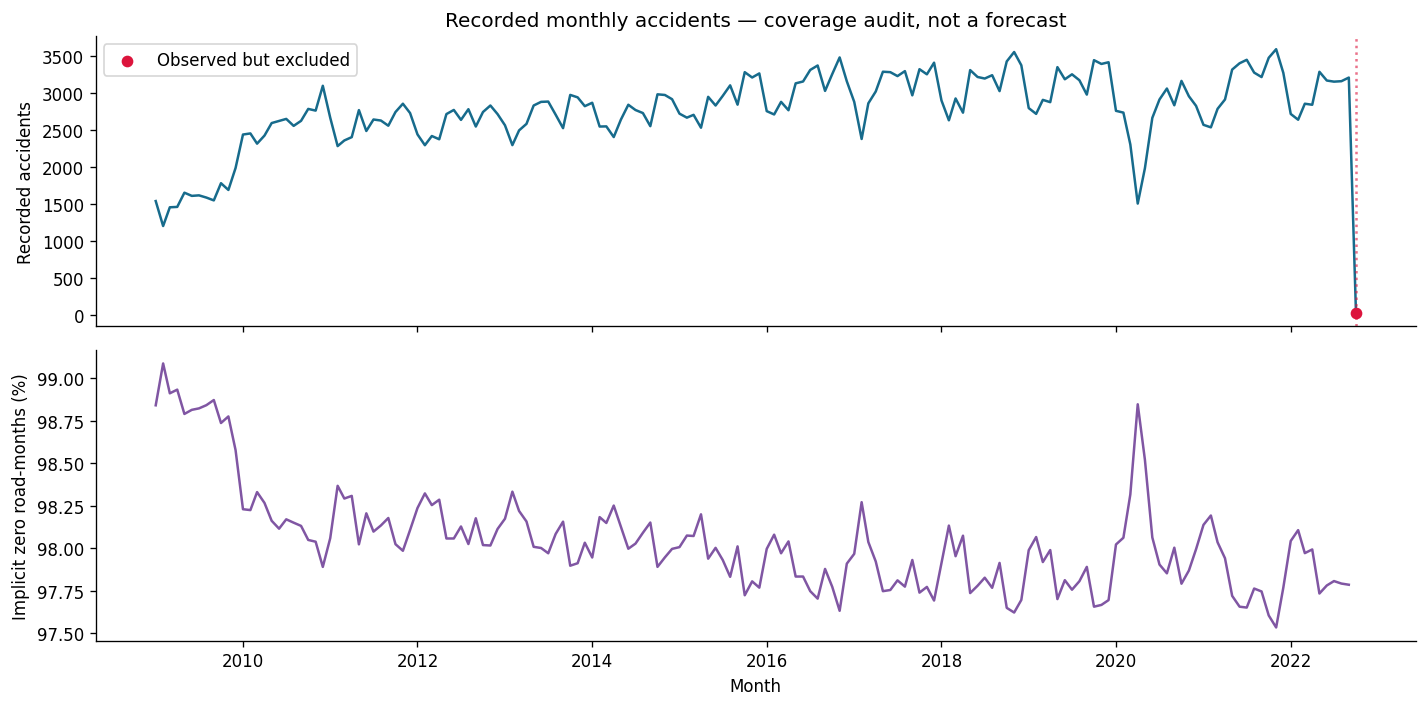

In [3]:
audit = data.monthly_audit
dates = data.months.to_timestamp()
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(dates, audit.recorded_accidents, color='#176b8c', lw=1.5)
suspect = data.observed_month & ~data.usable_month
axes[0].scatter(dates[suspect], audit.loc[suspect, 'recorded_accidents'], color='crimson', label='Observed but excluded', zorder=5)
axes[0].axvline(pd.Timestamp('2022-10-01'), color='crimson', ls=':', alpha=.6)
axes[0].set(title='Recorded monthly accidents — coverage audit, not a forecast', ylabel='Recorded accidents')
axes[0].legend()
axes[1].plot(dates, 100 * audit.implicit_zero_fraction, color='#8056a3')
axes[1].set(ylabel='Implicit zero road-months (%)', xlabel='Month')
save_figure(fig, '01_monthly_coverage.png')

## 3. Understand sparsity before building a predictor

The denominator includes all ordered graph edges, not only roads that had an accident.
Percentages therefore describe the supplied benchmark representation, not necessarily
distinct physical roads. No accident count is inferred for an unavailable month.

Provisional development months: 120
Ordered road-month observations: 13,943,520
Implicit zero fraction: 98.09%
Positive road-month fraction: 1.91%


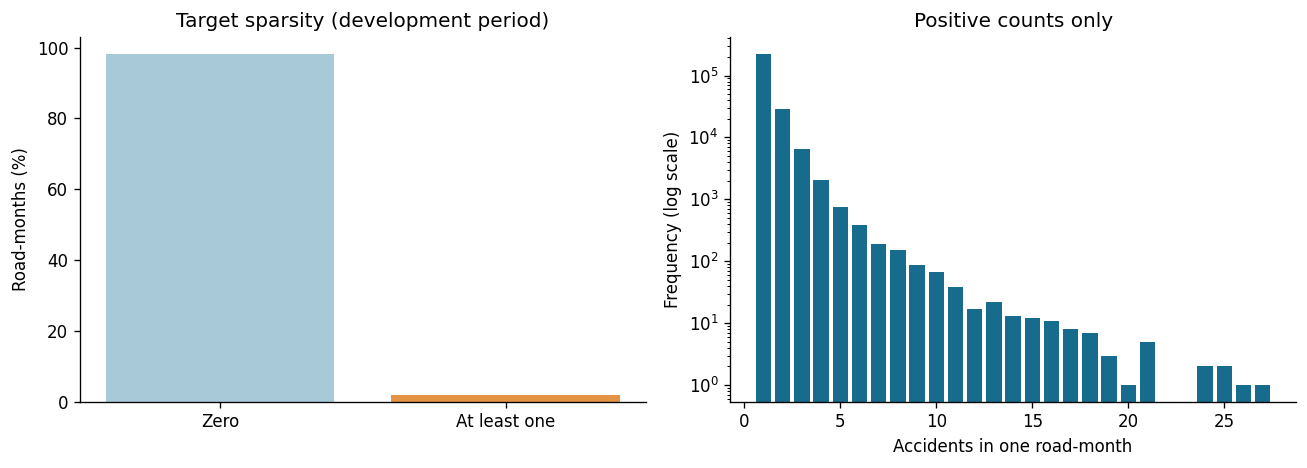

In [4]:
eda_mask = data.usable_month & np.asarray(data.months <= pd.Period(EDA_END_MONTH, 'M'))
eda_counts = data.counts[eda_mask]
frequency = np.bincount(eda_counts.ravel())
n_rows = int(eda_counts.size)
zero_fraction = float(frequency[0] / n_rows)
print(f'Provisional development months: {eda_mask.sum()}')
print(f'Ordered road-month observations: {n_rows:,}')
print(f'Implicit zero fraction: {zero_fraction:.2%}')
print(f'Positive road-month fraction: {1-zero_fraction:.2%}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(['Zero', 'At least one'], [zero_fraction*100, (1-zero_fraction)*100], color=['#a8c9d8', '#e39342'])
axes[0].set(title='Target sparsity (development period)', ylabel='Road-months (%)')
axes[1].bar(np.arange(1, len(frequency)), frequency[1:], color='#176b8c')
axes[1].set_yscale('log')
axes[1].set(title='Positive counts only', xlabel='Accidents in one road-month', ylabel='Frequency (log scale)')
save_figure(fig, '02_target_sparsity.png')

## 4. Directionality: do two directed edges behave like two physical roads?

The benchmark graph stores an ordered pair such as A→B as one edge and B→A as
another. Those are separate prediction rows, but the accident matching process may
not identify the vehicle's actual travel direction. We compare the original directed
road-month units with unordered endpoint pairs, and check whether accidents on a
two-way connection appear on one or both directed edges. A physical pair here means
only the two endpoint IDs sorted into one key; it is not a recovered OSM way.

The one-direction statistic below is cumulative over each displayed time window:
it asks whether a two-way connection ever has accidents recorded on both directions.
The monthly statistic separately checks whether both directions receive a positive
record in the same month. Neither statistic changes the labels used in the exports.

,window,months,directed_zero_fraction,physical_connections,physical_zero_fraction,two_way_physical_connections,two_way_with_accidents_cumulative,two_way_accidents_only_one_direction_cumulative,one_direction_only_share_cumulative,two_way_accidents_total,two_way_accidents_lower_to_higher,lower_to_higher_accident_share,two_way_positive_road_months,two_way_positive_road_months_both_directions,both_directions_same_month_share
0,All usable (2009-01 to 2022-09),165,0.9804,65252,0.9652,50944,26092,26092,1.0,226041,217922,0.9641,198365,0,0.0
1,Paper training (2009-01 to 2012-12),48,0.9832,65252,0.9701,50944,15057,15057,1.0,55658,53795,0.9665,49329,0,0.0
2,Current provisional EDA (2009-01 to 2018-12),120,0.9809,65252,0.9661,50944,23239,23239,1.0,159575,153940,0.9647,140238,0,0.0


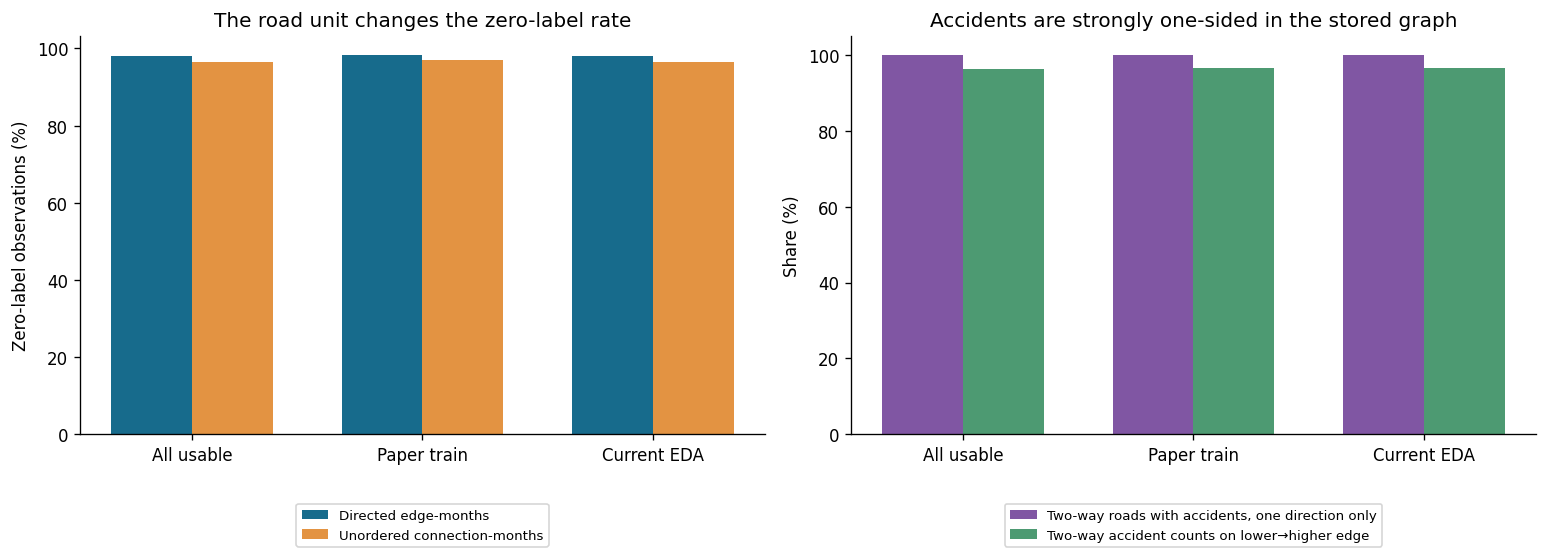

In [5]:
edge_pairs = data.edges[['node_1_idx', 'node_2_idx']].to_numpy()
physical_pairs, physical_group_for_edge = np.unique(
    np.sort(edge_pairs, axis=1), axis=0, return_inverse=True
)
n_physical = len(physical_pairs)
physical_group_size = np.bincount(physical_group_for_edge, minlength=n_physical)
two_way_physical = (physical_group_size == 2) & (physical_pairs[:, 0] != physical_pairs[:, 1])
two_way_edge = two_way_physical[physical_group_for_edge]
low_to_high_edge = edge_pairs[:, 0] < edge_pairs[:, 1]

assert physical_group_size.max() <= 2, 'Unexpected duplicate ordered endpoint pairs in the graph'

direction_windows = {
    'All usable (2009-01 to 2022-09)': data.usable_month,
    'Paper training (2009-01 to 2012-12)': data.usable_month & np.asarray(data.months <= pd.Period('2012-12', 'M')),
    'Current provisional EDA (2009-01 to 2018-12)': eda_mask,
}

direction_rows = []
for window_name, month_mask in direction_windows.items():
    window_counts = data.counts[month_mask]
    edge_totals = window_counts.sum(axis=0, dtype=np.int64)
    physical_totals = np.bincount(physical_group_for_edge, weights=edge_totals,
                                  minlength=n_physical)
    physical_sides_with_accidents = np.bincount(
        physical_group_for_edge, weights=(edge_totals > 0), minlength=n_physical
    )
    active_two_way = two_way_physical & (physical_totals > 0)
    n_active_two_way = int(active_two_way.sum())
    n_one_sided = int((physical_sides_with_accidents[active_two_way] == 1).sum())
    two_way_accidents = int(edge_totals[two_way_edge].sum())
    low_to_high_accidents = int(edge_totals[two_way_edge & low_to_high_edge].sum())

    physical_positive_road_months = 0
    two_way_road_months_with_accidents = 0
    two_way_road_months_both_directions = 0
    for month_counts in window_counts:
        month_physical_totals = np.bincount(
            physical_group_for_edge, weights=month_counts, minlength=n_physical
        )
        month_sides = np.bincount(
            physical_group_for_edge, weights=(month_counts > 0), minlength=n_physical
        )
        active_month = two_way_physical & (month_physical_totals > 0)
        physical_positive_road_months += int(np.count_nonzero(month_physical_totals))
        two_way_road_months_with_accidents += int(active_month.sum())
        two_way_road_months_both_directions += int((active_month & (month_sides == 2)).sum())

    direction_rows.append({
        'window': window_name,
        'months': int(month_mask.sum()),
        'directed_zero_fraction': float((window_counts == 0).mean()),
        'physical_connections': n_physical,
        'physical_zero_fraction': 1 - physical_positive_road_months / (n_physical * len(window_counts)),
        'two_way_physical_connections': int(two_way_physical.sum()),
        'two_way_with_accidents_cumulative': n_active_two_way,
        'two_way_accidents_only_one_direction_cumulative': n_one_sided,
        'one_direction_only_share_cumulative': n_one_sided / n_active_two_way if n_active_two_way else np.nan,
        'two_way_accidents_total': two_way_accidents,
        'two_way_accidents_lower_to_higher': low_to_high_accidents,
        'lower_to_higher_accident_share': low_to_high_accidents / two_way_accidents if two_way_accidents else np.nan,
        'two_way_positive_road_months': two_way_road_months_with_accidents,
        'two_way_positive_road_months_both_directions': two_way_road_months_both_directions,
        'both_directions_same_month_share': (
            two_way_road_months_both_directions / two_way_road_months_with_accidents
            if two_way_road_months_with_accidents else np.nan
        ),
    })

directionality_audit = pd.DataFrame(direction_rows)
display(directionality_audit.round(4))
directionality_audit.to_csv(OUTPUT_DIR / 'directionality_audit.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
positions = np.arange(len(directionality_audit))
width = 0.35
axes[0].bar(positions - width/2, 100*directionality_audit.directed_zero_fraction,
            width, label='Directed edge-months', color='#176b8c')
axes[0].bar(positions + width/2, 100*directionality_audit.physical_zero_fraction,
            width, label='Unordered connection-months', color='#e39342')
axes[0].set(xticks=positions, xticklabels=['All usable', 'Paper train', 'Current EDA'],
            ylabel='Zero-label observations (%)', title='The road unit changes the zero-label rate')
axes[0].legend(loc='lower center', bbox_to_anchor=(0.5, -0.30), fontsize=8)
axes[1].bar(positions - width/2,
            100*directionality_audit.one_direction_only_share_cumulative,
            width, label='Two-way roads with accidents, one direction only', color='#8056a3')
axes[1].bar(positions + width/2,
            100*directionality_audit.lower_to_higher_accident_share,
            width, label='Two-way accident counts on lower→higher edge', color='#4d9a72')
axes[1].set(xticks=positions, xticklabels=['All usable', 'Paper train', 'Current EDA'],
            ylim=(0, 105), ylabel='Share (%)', title='Accidents are strongly one-sided in the stored graph')
axes[1].legend(loc='lower center', bbox_to_anchor=(0.5, -0.30), fontsize=8)
fig.subplots_adjust(bottom=0.34, wspace=0.30)
save_figure(fig, '06_directionality_audit.png')

## 5. Feature definitions

For target month T, **all accident-derived inputs stop at T−1**. A three-month mean
uses T−3, T−2 and T−1. Full windows are required: insufficient or unavailable history
produces NaN, not zero. An availability feature is exported so downstream code can
distinguish limited history from a road with no observed accidents.

Neighbours are distinct **unordered endpoint connections sharing an intersection**.
Reverse orientations are combined for the neighbour statistic only, and the target's
own connection (including its reverse) is excluded. This avoids duplicate neighbours.
It is not a directed traffic-flow definition. Isolated roads receive neighbour mean 0
when history is known and `neighbor_count=0`.

In [6]:
definitions = [
    ('acc_lag_1m', 'Own ordered edge count in T-1', '1 completed month'),
    ('acc_mean_3m', 'Own mean over T-3 through T-1', '3 complete months'),
    ('acc_mean_6m', 'Own mean over T-6 through T-1', '6 complete months'),
    ('acc_mean_12m', 'Own mean over T-12 through T-1', '12 complete months'),
    ('acc_lag_12m', 'Own count in T-12', 'Month T-12 available'),
    ('acc_nonzero_fraction_12m', 'Fraction of prior 12 months with any accident', '12 complete months'),
    ('neighbor_acc_lag_1m_mean', 'Mean T-1 count over distinct neighbouring connections', '1 completed month'),
    ('neighbor_acc_mean_3m', 'Mean of the previous 3-month monthly averages across neighbours', '3 complete months'),
    ('neighbor_count', 'Number of distinct neighbouring connections', 'Static graph'),
    ('history_months_available_12m', 'Usable months among T-12 through T-1', 'Coverage metadata'),
]
dictionary = pd.DataFrame(definitions, columns=['feature', 'definition', 'requirement'])
display(dictionary)
dictionary.to_csv(OUTPUT_DIR / 'feature_dictionary.csv', index=False)

example_t = data.months.get_loc(pd.Period('2018-07', 'M'))
X_example = build_features(data.counts, data.usable_month, example_t, neighbours)
# Choose illustrative rows based on past history only, never on the target label.
example_ids = np.r_[np.argsort(-X_example[:, 1])[:5], np.flatnonzero(X_example[:, 1] == 0)[:3]]
example = data.edges.iloc[example_ids].reset_index(drop=True).copy()
example['target_month'] = str(data.months[example_t])
example = pd.concat([example, pd.DataFrame(X_example[example_ids], columns=FEATURE_NAMES)], axis=1)
example['TARGET_accidents_not_an_input'] = data.counts[example_t, example_ids]
display(example)
example.to_csv(OUTPUT_DIR / 'illustrative_feature_rows.csv', index=False)

,feature,definition,requirement
0,acc_lag_1m,Own ordered edge count in T-1,1 completed month
1,acc_mean_3m,Own mean over T-3 through T-1,3 complete months
2,acc_mean_6m,Own mean over T-6 through T-1,6 complete months
3,acc_mean_12m,Own mean over T-12 through T-1,12 complete months
4,acc_lag_12m,Own count in T-12,Month T-12 available
5,acc_nonzero_fraction_12m,Fraction of prior 12 months with any accident,12 complete months
6,neighbor_acc_lag_1m_mean,Mean T-1 count over distinct neighbouring conn...,1 completed month
7,neighbor_acc_mean_3m,Mean of the previous 3-month monthly averages ...,3 complete months
8,neighbor_count,Number of distinct neighbouring connections,Static graph
9,history_months_available_12m,Usable months among T-12 through T-1,Coverage metadata


,edge_id,node_1_idx,node_2_idx,node_1,node_2,target_month,acc_lag_1m,acc_mean_3m,acc_mean_6m,acc_mean_12m,acc_lag_12m,acc_nonzero_fraction_12m,neighbor_acc_lag_1m_mean,neighbor_acc_mean_3m,neighbor_count,history_months_available_12m,TARGET_accidents_not_an_input
0,116028,48932,18098,178700647,178618835,2018-07,24.0,15.333333,11.333333,14.000000,24.0,1.0,1.00,0.999999,2.0,12.0,19
1,43955,18093,29962,178618637,396462171,2018-07,8.0,13.333333,10.500000,11.333333,21.0,1.0,2.50,3.833333,4.0,12.0,13
2,79459,33059,18093,2140194699,178618637,2018-07,7.0,11.333333,10.166667,13.666667,18.0,1.0,2.25,4.083333,4.0,12.0,20
3,44740,18443,48823,178623785,178680553,2018-07,12.0,9.000000,7.833333,7.250000,5.0,1.0,2.25,1.666667,4.0,12.0,6
4,45319,18713,18441,178627781,178623772,2018-07,8.0,6.333333,5.166667,4.833333,1.0,1.0,3.25,2.000000,4.0,12.0,17
5,0,0,10,178623660,178661265,2018-07,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.00,0.000000,5.0,12.0,0
6,1,0,31,178623660,178703210,2018-07,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.00,0.000000,4.0,12.0,0
7,2,0,36,178623660,178706236,2018-07,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.00,0.000000,4.0,12.0,0


## 6. Feature distributions, availability and redundancy

This section describes the exported inputs themselves, not only their relation to
the target. Statistics are pooled over the provisional 2009–2018 development period
and use only features available before each target month. NaN means the required
history window is unavailable; it is not an accident count of zero. The benchmark
files in this directory do not contain a road-type column, so road-type-stratified
plots require the OSM feature table to be joined by verified endpoint IDs first.

,feature,finite_road_months,missing_share,zero_share_among_finite,mean,median,p90,p99,maximum
0,acc_lag_1m,13827324,0.0083,0.9810,0.0232,0.0,0.0000,1.0000,27.0000
1,acc_mean_3m,13594932,0.0250,0.9541,0.0233,0.0,0.0000,0.6667,24.0000
2,acc_mean_6m,13246344,0.0500,0.9256,0.0233,0.0,0.0000,0.5000,20.6667
3,acc_mean_12m,12549168,0.1000,0.8869,0.0235,0.0,0.0833,0.4167,16.8333
4,acc_lag_12m,12549168,0.1000,0.9812,0.0229,0.0,0.0000,1.0000,27.0000
5,acc_nonzero_fraction_12m,12549168,0.1000,0.8869,0.0193,0.0,0.0833,0.3333,1.0000
6,neighbor_acc_lag_1m_mean,13827324,0.0083,0.8857,0.0369,0.0,0.1667,0.5000,10.5000
7,neighbor_acc_mean_3m,13594932,0.0250,0.7658,0.0369,0.0,0.1333,0.4444,10.0000
8,neighbor_count,13943520,0.0000,0.0006,3.9803,4.0,5.0000,6.0000,10.0000
9,history_months_available_12m,13943520,0.0000,0.0083,11.3500,12.0,12.0000,12.0000,12.0000


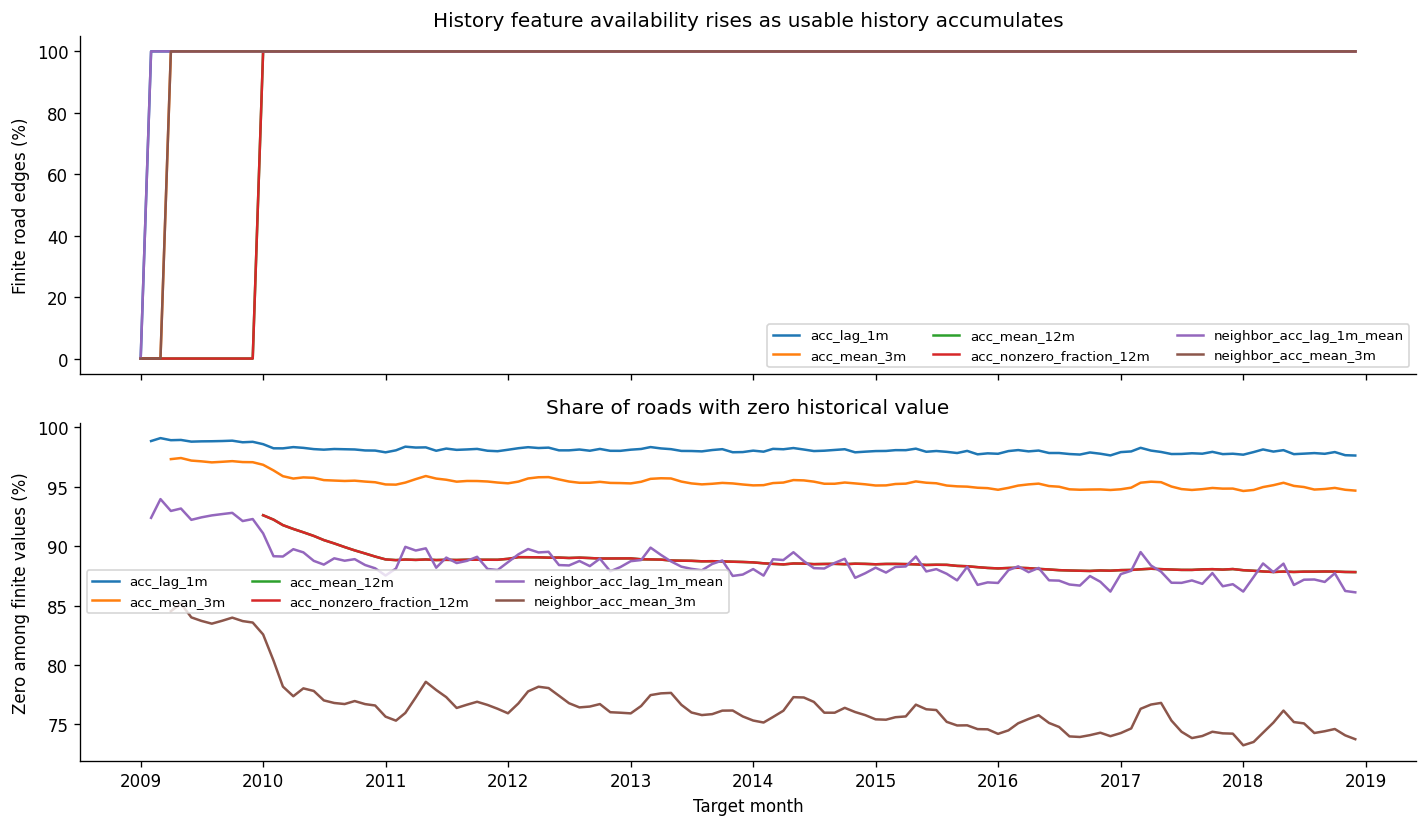

,acc_lag_1m,acc_mean_3m,acc_mean_6m,acc_mean_12m,acc_lag_12m,acc_nonzero_fraction_12m,neighbor_acc_lag_1m_mean,neighbor_acc_mean_3m,neighbor_count,history_months_available_12m
acc_lag_1m,1.00,0.64,0.50,0.41,0.21,0.41,0.14,0.16,0.09,0.02
acc_mean_3m,0.64,1.00,0.78,0.64,0.26,0.64,0.19,0.23,0.14,0.02
acc_mean_6m,0.50,0.78,1.00,0.81,0.28,0.81,0.22,0.27,0.18,0.02
acc_mean_12m,0.41,0.64,0.81,1.00,0.40,1.00,0.24,0.30,0.21,NaN
acc_lag_12m,0.21,0.26,0.28,0.40,1.00,0.40,0.13,0.15,0.09,NaN
acc_nonzero_fraction_12m,0.41,0.64,0.81,1.00,0.40,1.00,0.24,0.30,0.21,NaN
neighbor_acc_lag_1m_mean,0.14,0.19,0.22,0.24,0.13,0.24,1.00,0.69,0.20,0.04
neighbor_acc_mean_3m,0.16,0.23,0.27,0.30,0.15,0.30,0.69,1.00,0.26,0.05
neighbor_count,0.09,0.14,0.18,0.21,0.09,0.21,0.20,0.26,1.00,0.00
history_months_available_12m,0.02,0.02,0.02,NaN,NaN,NaN,0.04,0.05,0.00,1.00


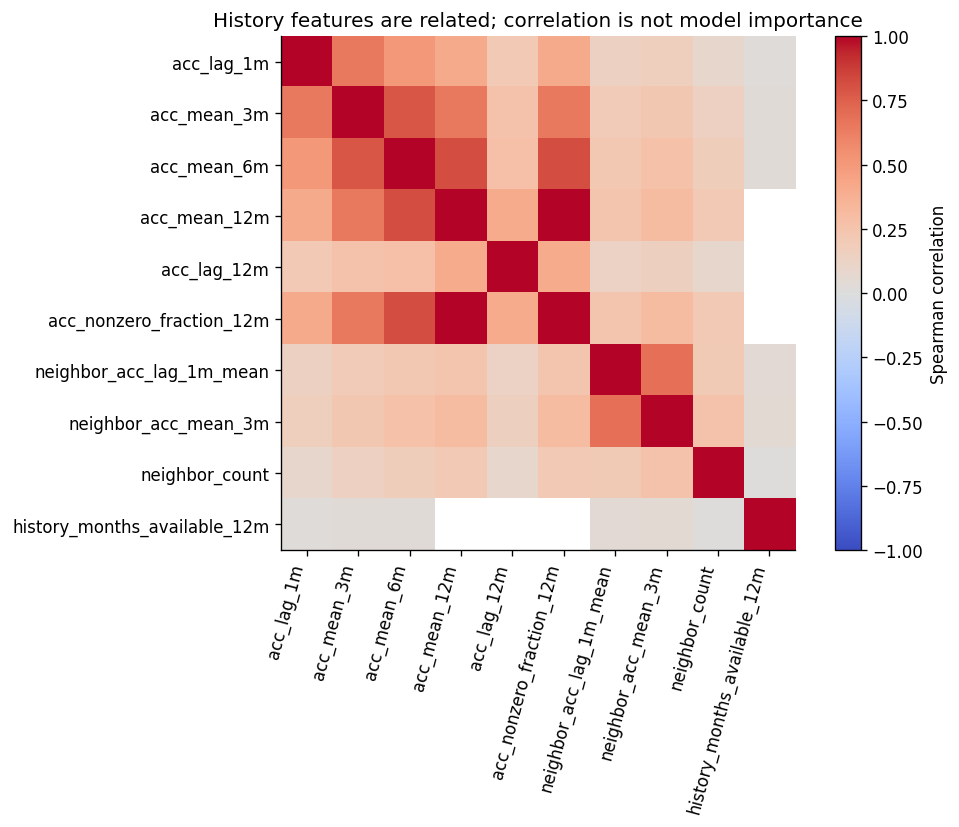

In [7]:
feature_rows = []
feature_month_rows = []
feature_samples = {name: [] for name in FEATURE_NAMES}
for t in np.flatnonzero(eda_mask):
    X_t = build_features(data.counts, data.usable_month, t, neighbours)
    for j, name in enumerate(FEATURE_NAMES):
        values = X_t[:, j]
        finite = values[np.isfinite(values)]
        feature_month_rows.append({'month': str(data.months[t]), 'feature': name,
            'finite_share': len(finite) / len(values),
            'zero_share_among_finite': float(np.mean(finite == 0)) if len(finite) else np.nan,
            'mean': float(np.mean(finite)) if len(finite) else np.nan,
            'median': float(np.median(finite)) if len(finite) else np.nan})
        if len(finite):
            feature_samples[name].append(finite)
for name, pieces in feature_samples.items():
    values = np.concatenate(pieces) if pieces else np.array([], dtype=float)
    feature_rows.append({'feature': name, 'finite_road_months': len(values),
        'missing_share': 1 - len(values) / (int(eda_mask.sum()) * len(data.edges)),
        'zero_share_among_finite': float(np.mean(values == 0)) if len(values) else np.nan,
        'mean': float(np.mean(values)) if len(values) else np.nan,
        'median': float(np.median(values)) if len(values) else np.nan,
        'p90': float(np.quantile(values, .90)) if len(values) else np.nan,
        'p99': float(np.quantile(values, .99)) if len(values) else np.nan,
        'maximum': float(np.max(values)) if len(values) else np.nan})
feature_profile = pd.DataFrame(feature_rows)
feature_monthly = pd.DataFrame(feature_month_rows)
display(feature_profile.round(4))
feature_profile.to_csv(OUTPUT_DIR / 'development_feature_profile.csv', index=False)
feature_monthly.to_csv(OUTPUT_DIR / 'monthly_feature_profile.csv', index=False)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for name in ['acc_lag_1m', 'acc_mean_3m', 'acc_mean_12m', 'acc_nonzero_fraction_12m',
             'neighbor_acc_lag_1m_mean', 'neighbor_acc_mean_3m']:
    block = feature_monthly[feature_monthly.feature == name]
    axes[0].plot(pd.to_datetime(block.month), block.finite_share * 100, label=name)
    axes[1].plot(pd.to_datetime(block.month), block.zero_share_among_finite * 100, label=name)
axes[0].set(ylabel='Finite road edges (%)', title='History feature availability rises as usable history accumulates')
axes[1].set(ylabel='Zero among finite values (%)', xlabel='Target month', title='Share of roads with zero historical value')
axes[0].legend(ncol=3, fontsize=8)
axes[1].legend(ncol=3, fontsize=8)
save_figure(fig, '07_feature_availability_and_zeros.png')

# Correlations are descriptive and computed pairwise on the same edge-month rows.
profile_months = np.flatnonzero(eda_mask)
sample_parts = []
for t in profile_months:
    X_t = build_features(data.counts, data.usable_month, t, neighbours)
    sample_parts.append(X_t[::10])  # deterministic 10% edge sample to bound memory
profile_sample = np.vstack(sample_parts)
profile_frame = pd.DataFrame(profile_sample, columns=FEATURE_NAMES)
feature_corr = profile_frame.corr(method='spearman', min_periods=1000)
display(feature_corr.round(2))
feature_corr.to_csv(OUTPUT_DIR / 'development_feature_spearman.csv')
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(feature_corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=75, ha='right')
ax.set_yticks(range(len(FEATURE_NAMES)), FEATURE_NAMES)
fig.colorbar(im, ax=ax, label='Spearman correlation')
ax.set_title('History features are related; correlation is not model importance')
save_figure(fig, '08_feature_spearman.png')

## 7. Do roads with accident history have more future accidents?

For each eligible development month, group roads using only the preceding three
months' accident **total**, then summarize the actual target-month outcomes.
Every zero-history road-month is retained. This is descriptive association, not
causal evidence or held-out predictive performance. Counts are not exposure-adjusted:
long/busy roads may have both more history and more future accidents.

,prior_3m_total,road_months,mean_target_count,target_accident_rate
0,0,12970670,0.012133,0.011202
1,1,455189,0.151733,0.128593
2,2,102731,0.333804,0.256602
3,3–5,56201,0.656358,0.428284
4,6+,10141,2.229760,0.770338


period,2009–2012,2013–2015,2016–2018
prior_3m_total,,,
0,0.0103,0.0115,0.0120
1,0.1252,0.1273,0.1334
2,0.2481,0.2540,0.2673
3–5,0.4205,0.4278,0.4355
6+,0.7561,0.7618,0.7870


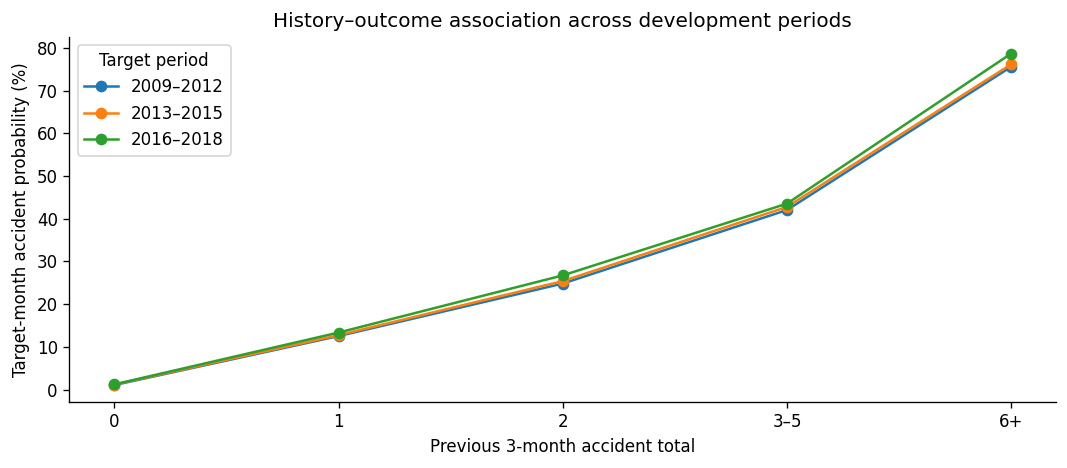

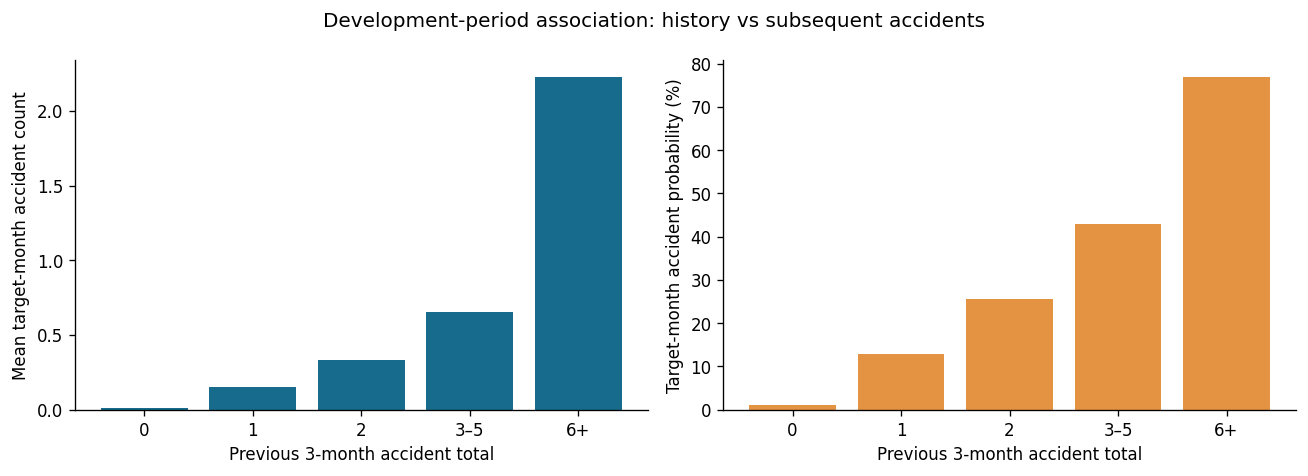

In [8]:
labels = ['0', '1', '2', '3–5', '6+']
bucket_n = np.zeros(5, dtype=np.int64)
bucket_sum = np.zeros(5, dtype=np.float64)
bucket_positive = np.zeros(5, dtype=np.int64)
for t in np.flatnonzero(eda_mask):
    if t < 3 or not data.usable_month[t-3:t].all():
        continue
    past_total = data.counts[t-3:t].sum(axis=0)
    bucket = np.digitize(past_total, [1, 2, 3, 6])
    y = data.counts[t]
    bucket_n += np.bincount(bucket, minlength=5)
    bucket_sum += np.bincount(bucket, weights=y, minlength=5)
    bucket_positive += np.bincount(bucket, weights=(y > 0), minlength=5).astype(np.int64)
risk_by_history = pd.DataFrame({
    'prior_3m_total': labels, 'road_months': bucket_n,
    'mean_target_count': np.divide(bucket_sum, bucket_n, out=np.full(5, np.nan), where=bucket_n>0),
    'target_accident_rate': np.divide(bucket_positive, bucket_n, out=np.full(5, np.nan), where=bucket_n>0),
})
display(risk_by_history)
risk_by_history.to_csv(OUTPUT_DIR / 'development_risk_by_history.csv', index=False)

# Check whether the pooled association is similar across broad calendar periods.
period_defs = [('2009–2012', '2009-01', '2012-12'),
               ('2013–2015', '2013-01', '2015-12'),
               ('2016–2018', '2016-01', '2018-12')]
period_risk_rows = []
for period_name, first_month, last_month in period_defs:
    n = np.zeros(5, dtype=np.int64)
    positive = np.zeros(5, dtype=np.int64)
    target_sum = np.zeros(5, dtype=np.float64)
    for t in np.flatnonzero(eda_mask):
        if not (pd.Period(first_month, 'M') <= data.months[t] <= pd.Period(last_month, 'M')):
            continue
        if t < 3 or not data.usable_month[t-3:t].all():
            continue
        bucket = np.digitize(data.counts[t-3:t].sum(axis=0), [1, 2, 3, 6])
        y = data.counts[t]
        n += np.bincount(bucket, minlength=5)
        positive += np.bincount(bucket, weights=(y > 0), minlength=5).astype(np.int64)
        target_sum += np.bincount(bucket, weights=y, minlength=5)
    for i, label in enumerate(labels):
        period_risk_rows.append({'period': period_name, 'prior_3m_total': label,
            'road_months': int(n[i]), 'target_accident_rate': positive[i] / n[i] if n[i] else np.nan,
            'mean_target_count': target_sum[i] / n[i] if n[i] else np.nan})
period_risk = pd.DataFrame(period_risk_rows)
display(period_risk.pivot(index='prior_3m_total', columns='period', values='target_accident_rate').round(4))
period_risk.to_csv(OUTPUT_DIR / 'development_risk_by_period.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 4))
for period_name, block in period_risk.groupby('period', sort=False):
    ax.plot(block.prior_3m_total, 100 * block.target_accident_rate, marker='o', label=period_name)
ax.set(xlabel='Previous 3-month accident total', ylabel='Target-month accident probability (%)',
       title='History–outcome association across development periods')
ax.legend(title='Target period')
save_figure(fig, '09_history_association_by_period.png')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(labels, risk_by_history.mean_target_count, color='#176b8c')
axes[0].set(ylabel='Mean target-month accident count', xlabel='Previous 3-month accident total')
axes[1].bar(labels, 100*risk_by_history.target_accident_rate, color='#e39342')
axes[1].set(ylabel='Target-month accident probability (%)', xlabel='Previous 3-month accident total')
fig.suptitle('Development-period association: history vs subsequent accidents')
save_figure(fig, '03_history_association.png')

## 8. Does neighbour history contain a signal for roads without recent accidents?

Restrict to road-months with **zero own-road accidents in the previous three months**.
Compare those with no neighbouring accidents to those with some neighbouring accidents.
Isolated roads form a separate group. This reduces one obvious confounder (own history)
but does not establish that adding the feature improves an MLP or GNN.

,group,road_months,mean_target_count,target_accident_rate
0,No neighbours,8443,0.003672,0.003435
1,"Neighbours, no recent accidents",10179797,0.006437,0.006100
2,"Neighbours, recent accidents",2782430,0.033001,0.029891


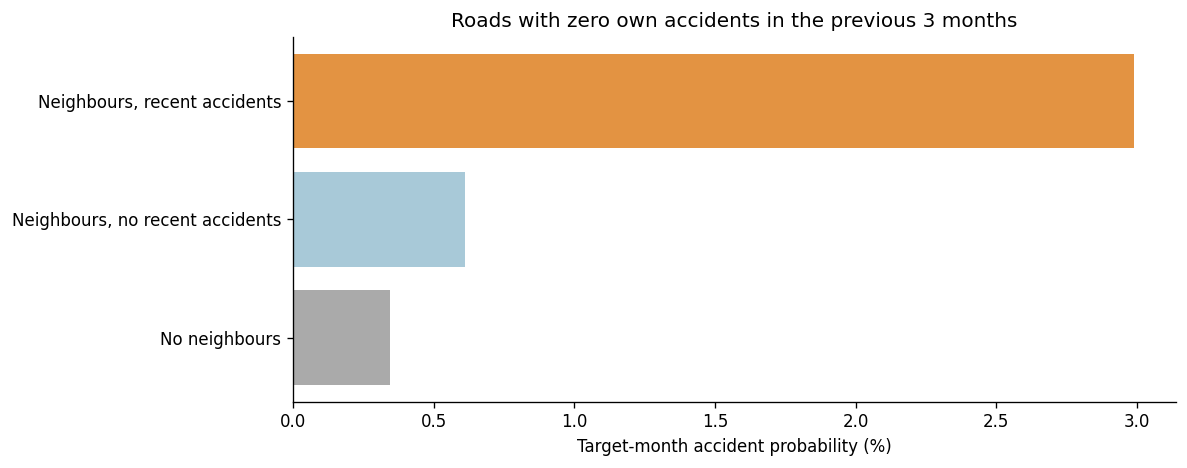

In [9]:
neighbor_labels = ['No neighbours', 'Neighbours, no recent accidents', 'Neighbours, recent accidents']
nn = np.zeros(3, dtype=np.int64)
ny = np.zeros(3, dtype=np.float64)
np_event = np.zeros(3, dtype=np.int64)
for t in np.flatnonzero(eda_mask):
    if t < 3 or not data.usable_month[t-3:t].all():
        continue
    past = data.counts[t-3:t].mean(axis=0, dtype=np.float32)
    own_zero = past == 0
    neighbour_past = neighbours.mean(past)
    group = np.where(neighbours.edge_degree == 0, 0, np.where(neighbour_past == 0, 1, 2))
    y, g = data.counts[t, own_zero], group[own_zero]
    nn += np.bincount(g, minlength=3)
    ny += np.bincount(g, weights=y, minlength=3)
    np_event += np.bincount(g, weights=(y > 0), minlength=3).astype(np.int64)
neighbor_summary = pd.DataFrame({'group': neighbor_labels, 'road_months': nn,
    'mean_target_count': np.divide(ny, nn, out=np.full(3, np.nan), where=nn>0),
    'target_accident_rate': np.divide(np_event, nn, out=np.full(3, np.nan), where=nn>0)})
display(neighbor_summary)
neighbor_summary.to_csv(OUTPUT_DIR / 'development_neighbour_association.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(neighbor_labels, 100*neighbor_summary.target_accident_rate, color=['#aaa', '#a8c9d8', '#e39342'])
ax.set(xlabel='Target-month accident probability (%)', title='Roads with zero own accidents in the previous 3 months')
save_figure(fig, '04_neighbour_association.png')

## 9. Fixed versus rolling windows: show the difference before selecting one

Illustrative fixed reference: **2009–2013**, used only for target months in 2014 or
later. Rolling references update using the previous 3 or 12 months. The example road
is selected using 2009–2013 counts only. Short windows react faster; long windows are
smoother. Which performs best must be selected on the team's validation split.

The plot shows historical estimates, not a fitted model. Do not describe the plotted
curves as evidence that one window is more accurate on held-out data.

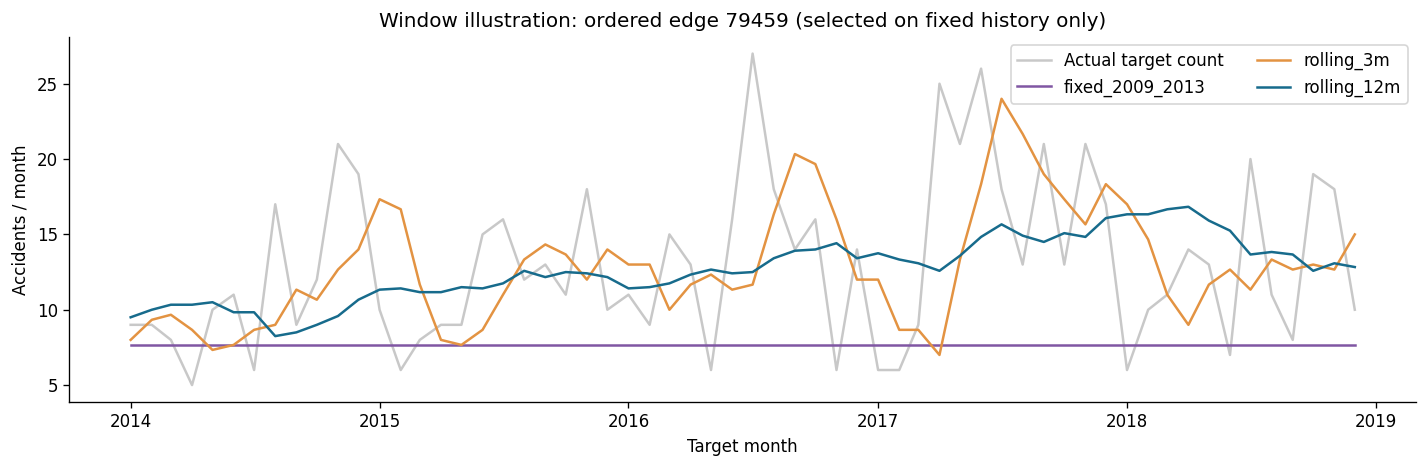

In [10]:
fixed_stop = data.months.get_loc(pd.Period('2014-01', 'M'))
road_id = int(data.counts[:fixed_stop].sum(axis=0).argmax())
fixed = fixed_history_mean(data.counts, data.usable_month, 0, fixed_stop, fixed_stop)
trajectory = []
for t in np.flatnonzero(eda_mask):
    if t < fixed_stop:
        continue
    # All windows end before t; preserve missing-month checks.
    m3 = data.counts[t-3:t, road_id].mean() if data.usable_month[t-3:t].all() else np.nan
    m12 = data.counts[t-12:t, road_id].mean() if data.usable_month[t-12:t].all() else np.nan
    trajectory.append((data.months[t].to_timestamp(), data.counts[t, road_id], fixed[road_id], m3, m12))
trajectory = pd.DataFrame(trajectory, columns=['month', 'actual', 'fixed_2009_2013', 'rolling_3m', 'rolling_12m']).set_index('month')
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(trajectory.index, trajectory.actual, color='#bbb', alpha=.8, label='Actual target count')
for column, color in [('fixed_2009_2013', '#8056a3'), ('rolling_3m', '#e39342'), ('rolling_12m', '#176b8c')]:
    ax.plot(trajectory.index, trajectory[column], label=column, color=color)
ax.set(title=f'Window illustration: ordered edge {road_id} (selected on fixed history only)', ylabel='Accidents / month', xlabel='Target month')
ax.legend(ncol=2)
save_figure(fig, '05_fixed_vs_rolling.png')
trajectory.to_csv(OUTPUT_DIR / 'window_example.csv')

## 10. Leakage checks and walk-forward interface

Meaningful checks: exact lag arithmetic; unavailable months; early-history NaNs;
reverse-edge/self-loop/isolated-road handling; and invariance when target/future labels
are changed. Full-data checks additionally confirm feature ordering and manual means.

For monthly walk-forward forecasts, July labels may inform August features only after
July reports are available. Model retraining is a separate choice. Confirm with the
baseline owner whether weights stay frozen or are refit at each origin, and keep the
same policy across ablations. Do not use test labels for hyperparameter selection.

In [11]:
checks = run_self_checks()
t = example_t
manual = data.counts[t-3:t, example_ids].mean(axis=0)
np.testing.assert_allclose(X_example[example_ids, FEATURE_NAMES.index('acc_mean_3m')], manual)
changed_counts = data.counts.copy()
changed_counts[t:] = 12345
np.testing.assert_allclose(X_example, build_features(changed_counts, data.usable_month, t, neighbours), equal_nan=True)
del changed_counts
checks['real_data_manual_3m_average'] = 'passed'
checks['real_data_target_and_future_invariance'] = 'passed'
assert len(data.edges) == X_example.shape[0]
checks['edge_alignment'] = 'passed'
display(pd.Series(checks, name='result').to_frame())
(OUTPUT_DIR / 'validation_checks.json').write_text(json.dumps(checks, indent=2))

# Interface demonstration only: these are not official evaluation dates.
demo_origins = []
for t, past_indices in walk_forward_indices(data.months, data.usable_month, '2018-07', '2018-09'):
    assert np.all(past_indices < t)
    demo_origins.append({'target_month': str(data.months[t]),
                         'latest_allowed_accident_month': str(data.months[past_indices[-1]])})
display(pd.DataFrame(demo_origins))

,result
past_only_and_future_mutation,passed
exact_lags_and_windows,passed
missing_month_and_warmup,passed
neighbours_reverse_loop_isolated,passed
fixed_reference_cutoff,passed
real_data_manual_3m_average,passed
real_data_target_and_future_invariance,passed
edge_alignment,passed


,target_month,latest_allowed_accident_month
0,2018-07,2018-06
1,2018-08,2018-07
2,2018-09,2018-08


## 11. Export features for teammates

Each usable month gets a compressed `.npz` with:

- `X`: [number of ordered edges, number of features], float32; **no labels inside X**.
- `y`: separate target-month counts; `edge_id`: identifiers for joining.
- `feature_names`, `target_month`, `history_cutoff`, `full_12m_history`.

`edge_mapping.csv` maps edge IDs to node indices and original OSM endpoint IDs.
The training loader verifies endpoint alignment before aggregating counts.
Keep raw features unchanged here. Fit imputation/scaling on training only, or remove
the common first-12-month warm-up for all compared variants.

Exports include later periods for future chronological experiments; do not use those
labels to choose features or windows. NPZ avoids a huge repeated-ID road-month CSV.

In [12]:
manifest = export_features(data, neighbours, OUTPUT_DIR)
manifest['provisional_eda_end_month'] = EDA_END_MONTH
manifest['directionality_by_window'] = directionality_audit.to_dict('records')
manifest['eda_artifacts'] = [
    'development_feature_profile.csv', 'monthly_feature_profile.csv',
    'development_feature_spearman.csv', 'development_risk_by_period.csv',
]
manifest['self_checks'] = checks
(OUTPUT_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2))
example_path = OUTPUT_DIR / 'monthly_features' / 'history_2018-07.npz'
with np.load(example_path, allow_pickle=False) as saved:
    np.testing.assert_allclose(saved['X'], X_example, equal_nan=True)
    np.testing.assert_array_equal(saved['y'], data.counts[example_t])
    np.testing.assert_array_equal(saved['edge_id'], data.edges.edge_id.to_numpy())
    print('X shape:', saved['X'].shape)
    print('Features:', saved['feature_names'].tolist())
    print('Target:', str(saved['target_month']), 'history ends:', str(saved['history_cutoff']))
print('Exported months:', manifest['feature_files'])
print('Archive manifest:', (OUTPUT_DIR / 'manifest.json').name)

X shape: (116196, 10)
Features: ['acc_lag_1m', 'acc_mean_3m', 'acc_mean_6m', 'acc_mean_12m', 'acc_lag_12m', 'acc_nonzero_fraction_12m', 'neighbor_acc_lag_1m_mean', 'neighbor_acc_mean_3m', 'neighbor_count', 'history_months_available_12m']
Target: 2018-07 history ends: 2018-06
Exported months: 165
Archive manifest: manifest.json


## 12. Findings and interpretation

The following summary describes ordered edges in the exploratory period. Correlated windows can encode similar information, and reporting or exposure changes can affect comparisons across periods. The final report evaluates full-history and no-history models on the same physical-road population and chronological splits, with classification and count regression reported separately.

In [13]:
summary = {
    'audit': data.audit,
    'provisional_eda_end_month': EDA_END_MONTH,
    'development_road_months': n_rows,
    'development_zero_fraction': zero_fraction,
    'directionality_by_window': directionality_audit.to_dict('records'),
    'feature_profile': feature_profile.to_dict('records'),
    'feature_spearman': feature_corr.round(4).to_dict(),
    'risk_by_own_history': risk_by_history.to_dict('records'),
    'risk_by_period': period_risk.to_dict('records'),
    'risk_by_neighbour_history_given_zero_own': neighbor_summary.to_dict('records'),
    'feature_files': manifest['feature_files'],
    'feature_count': len(FEATURE_NAMES),
    'checks': checks,
    'model_performance_evaluated': False,
}
(OUTPUT_DIR / 'eda_summary.json').write_text(json.dumps(summary, indent=2))
base = risk_by_history.iloc[0]
high = risk_by_history.iloc[-1]
print(f'Own history 0 accidents in preceding 3 months: next-month event rate {base.target_accident_rate:.2%} (n={base.road_months:,}).')
print(f'Own history 6+ accidents in preceding 3 months: next-month event rate {high.target_accident_rate:.2%} (n={high.road_months:,}).')
print('Feature profiles and pairwise Spearman correlations are descriptive; highly correlated windows may be redundant inputs.')
print('Temporal stability table reports associations by calendar period; differences can reflect changing reporting or exposure, not only feature behavior.')
for row in neighbor_summary.itertuples():
    print(f'{row.group}: event rate {row.target_accident_rate:.2%}, n={row.road_months:,}.')
full_direction = directionality_audit.iloc[0]
print(f"Two-way roads with any accidents: {full_direction.two_way_with_accidents_cumulative:,}; "
      f"one direction only over the full period: {full_direction.one_direction_only_share_cumulative:.2%}.")
print(f"Of accidents on two-way roads, {full_direction.lower_to_higher_accident_share:.2%} "
      "are stored on the lower-index to higher-index edge.")
print('These are pooled development-period associations, not held-out improvements.')

Own history 0 accidents in preceding 3 months: next-month event rate 1.12% (n=12,970,670).
Own history 6+ accidents in preceding 3 months: next-month event rate 77.03% (n=10,141).
Feature profiles and pairwise Spearman correlations are descriptive; highly correlated windows may be redundant inputs.
Temporal stability table reports associations by calendar period; differences can reflect changing reporting or exposure, not only feature behavior.
No neighbours: event rate 0.34%, n=8,443.
Neighbours, no recent accidents: event rate 0.61%, n=10,179,797.
Neighbours, recent accidents: event rate 2.99%, n=2,782,430.
Two-way roads with any accidents: 26,092; one direction only over the full period: 100.00%.
Of accidents on two-way roads, 96.41% are stored on the lower-index to higher-index edge.
These are pooled development-period associations, not held-out improvements.
